In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from src.config import (
    CLASSES,
    MODELS_DIR,
    SPLIT_MANIFEST_PATH
)

from src.preprocessing import dataset_from_manifest

print("TensorFlow:", tf.__version__)
print("Clases:", CLASSES)

I0000 00:00:1792009249.414764    9137 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792009249.426979    9137 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792009249.480636    9137 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792009251.251855    9137 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow: 2.21.0
Clases: ['OverRipe', 'Ripe', 'UnRipe']


# 2. Cargar el modelo

In [2]:
model_path = MODELS_DIR / "mango_final.keras"

print("Modelo:", model_path)
print("Existe:", model_path.exists())

Modelo: /home/kevin/Documentos/Django/Mango/models/mango_final.keras
Existe: True


In [3]:
model = tf.keras.models.load_model(model_path)

model.summary()

E0000 00:00:1792009252.858511    9137 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,515 (8.66 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 7,688 (30.04 KB)

# 3. Cargar el conjunto de test

In [4]:
split = pd.read_csv(
    SPLIT_MANIFEST_PATH
)

test_ds = dataset_from_manifest(
    split,
    "test",
    batch_size=8,
    augment=False
)

print(
    "Imágenes de test:",
    len(split[split["split"] == "test"])
)

Imágenes de test: 152


# 4. Obtener predicciones

In [5]:
y_true = []
y_pred = []

for images, labels in test_ds:
    
    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_classes
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predicciones realizadas:", len(y_pred))

Predicciones realizadas: 152


# 5. Accuracy

In [6]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

print(
    f"Accuracy: {accuracy:.4f}"
)

Accuracy: 0.9671


# 6. Precision, Recall y F1-score

In [7]:
precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Precision: 0.8233
Recall:    0.8595
F1-score:  0.8314


In [8]:
from sklearn.metrics import roc_auc_score

probabilidades = model.predict(test_ds, verbose=0)
auc = roc_auc_score(y_true, probabilidades, multi_class="ovr", labels=[0, 1, 2])

print(f"ROC-AUC (ovr): {auc:.4f}")

ROC-AUC (ovr): 0.9832


# 7. Reporte completo

In [9]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    OverRipe       0.75      0.60      0.67         5
        Ripe       0.73      1.00      0.84         8
      UnRipe       0.99      0.98      0.99       139

    accuracy                           0.97       152
   macro avg       0.82      0.86      0.83       152
weighted avg       0.97      0.97      0.97       152



# 8. Matriz de confusión

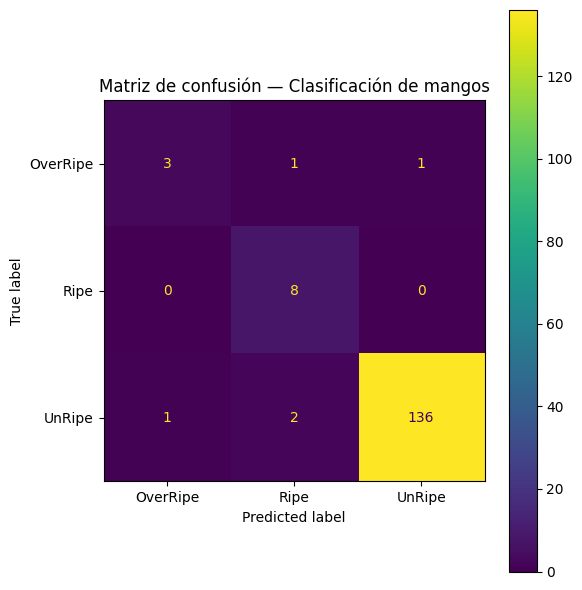

In [10]:
cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Matriz de confusión — Clasificación de mangos"
)

plt.tight_layout()
plt.show()

# 9. Ver predicciones reales

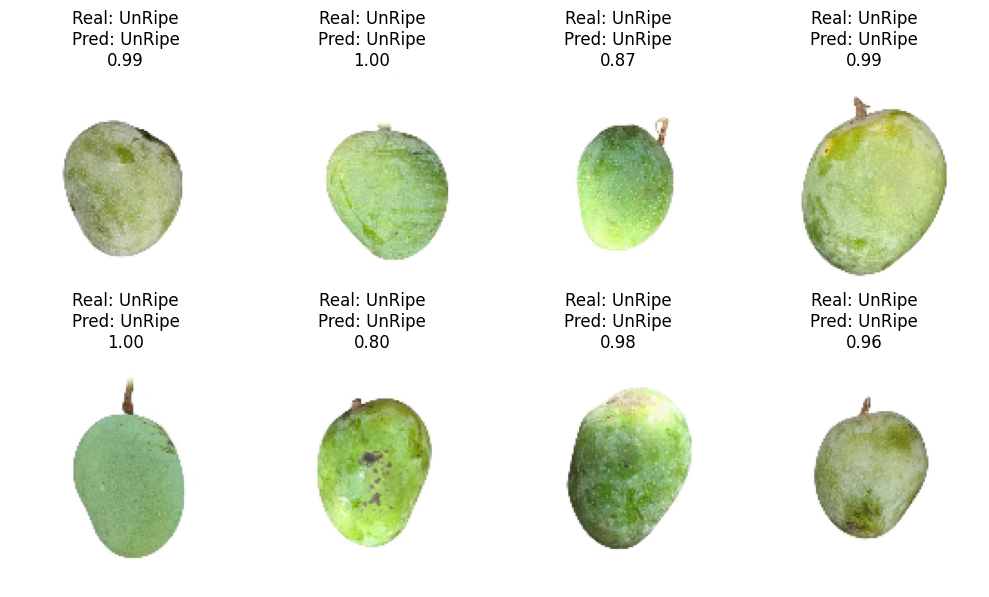

In [11]:
images, labels = next(iter(test_ds))

predictions = model.predict(
    images,
    verbose=0
)

predicted_classes = np.argmax(
    predictions,
    axis=1
)

plt.figure(figsize=(10, 6))

for i in range(len(images)):
    
    real = CLASSES[
        int(labels[i].numpy())
    ]
    
    pred = CLASSES[
        int(predicted_classes[i])
    ]
    
    probability = np.max(
        predictions[i]
    )

    plt.subplot(2, 4, i + 1)

    plt.imshow(
        images[i].numpy()
    )

    plt.title(
        f"Real: {real}\n"
        f"Pred: {pred}\n"
        f"{probability:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Resumen final de evaluación

In [12]:
results = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Valor": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

resultsresults = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Valor": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

results

,Métrica,Valor
0,Accuracy,0.967105
1,Precision,0.823324
2,Recall,0.859472
3,F1-score,0.831426
